# 1.0 – EDA

In [1]:
import sys, warnings
sys.path.append('../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image
import data_processing as dp
from data_processing import *
sns.set_theme(style='whitegrid')
FIG = FIGURES_DIR
def save(name): plt.tight_layout(); plt.savefig(FIG / name, dpi=130)

## Tổng quan dữ liệu

In [2]:
df = load_raw()
print('Số dòng, số cột:', df.shape)
print('Số id trùng:', df['id'].duplicated().sum())
print('Giá trị thiếu:'); print(df.isna().sum()[lambda s: s > 0])
display(df.head())
display(df.dtypes.to_frame('dtype').T)

Số dòng, số cột: (21613, 21)
Số id trùng: 177
Giá trị thiếu:
sqft_above    2
dtype: int64


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180.0,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170.0,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770.0,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050.0,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680.0,0,1987,0,98074,47.6168,-122.045,1800,7503


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
dtype,int64,str,float64,int64,float64,int64,int64,float64,int64,int64,...,int64,float64,int64,int64,int64,int64,float64,float64,int64,int64


In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,21613.0,4.580302e+09,2.876566e+09,1.000102e+06,2.123049e+09,3.904930e+09,7.308900e+09,9.900000e+09
price,21613.0,5.400881e+05,3.671272e+05,7.500000e+04,3.219500e+05,4.500000e+05,6.450000e+05,7.700000e+06
bedrooms,21613.0,3.370842e+00,9.300618e-01,0.000000e+00,3.000000e+00,3.000000e+00,4.000000e+00,3.300000e+01
bathrooms,21613.0,2.114757e+00,7.701632e-01,0.000000e+00,1.750000e+00,2.250000e+00,2.500000e+00,8.000000e+00
sqft_living,21613.0,2.079900e+03,9.184409e+02,2.900000e+02,1.427000e+03,1.910000e+03,2.550000e+03,1.354000e+04
sqft_lot,21613.0,1.510697e+04,4.142051e+04,5.200000e+02,5.040000e+03,7.618000e+03,1.068800e+04,1.651359e+06
floors,21613.0,1.494309e+00,5.399889e-01,1.000000e+00,1.000000e+00,1.500000e+00,2.000000e+00,3.500000e+00
waterfront,21613.0,7.541757e-03,8.651720e-02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
view,21613.0,2.343034e-01,7.663176e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.000000e+00
condition,21613.0,3.409430e+00,6.507430e-01,1.000000e+00,3.000000e+00,3.000000e+00,4.000000e+00,5.000000e+00


## Đơn biến

Tỷ lệ outlier theo IQR: 5.30%


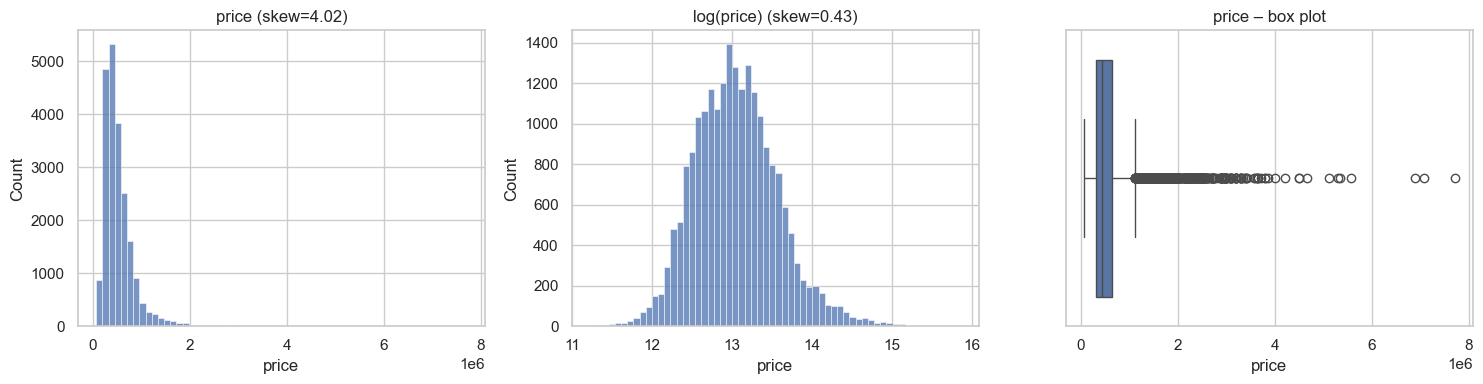

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df['price'], bins=60, ax=axes[0]); axes[0].set_title(f"price (skew={df['price'].skew():.2f})")
sns.histplot(np.log1p(df['price']), bins=60, ax=axes[1]); axes[1].set_title(f"log(price) (skew={np.log1p(df['price']).skew():.2f})")
sns.boxplot(x=df['price'], ax=axes[2]); axes[2].set_title('price – box plot')
save('eda_price_distribution.png')
q1, q3 = df['price'].quantile([.25, .75])
print(f"Tỷ lệ outlier theo IQR: {(df['price'] > q3 + 1.5*(q3-q1)).mean():.2%}")

sqft_living       1.47
sqft_lot         13.06
sqft_above        1.45
sqft_basement     1.58
sqft_living15     1.11
yr_built         -0.47
dtype: float64


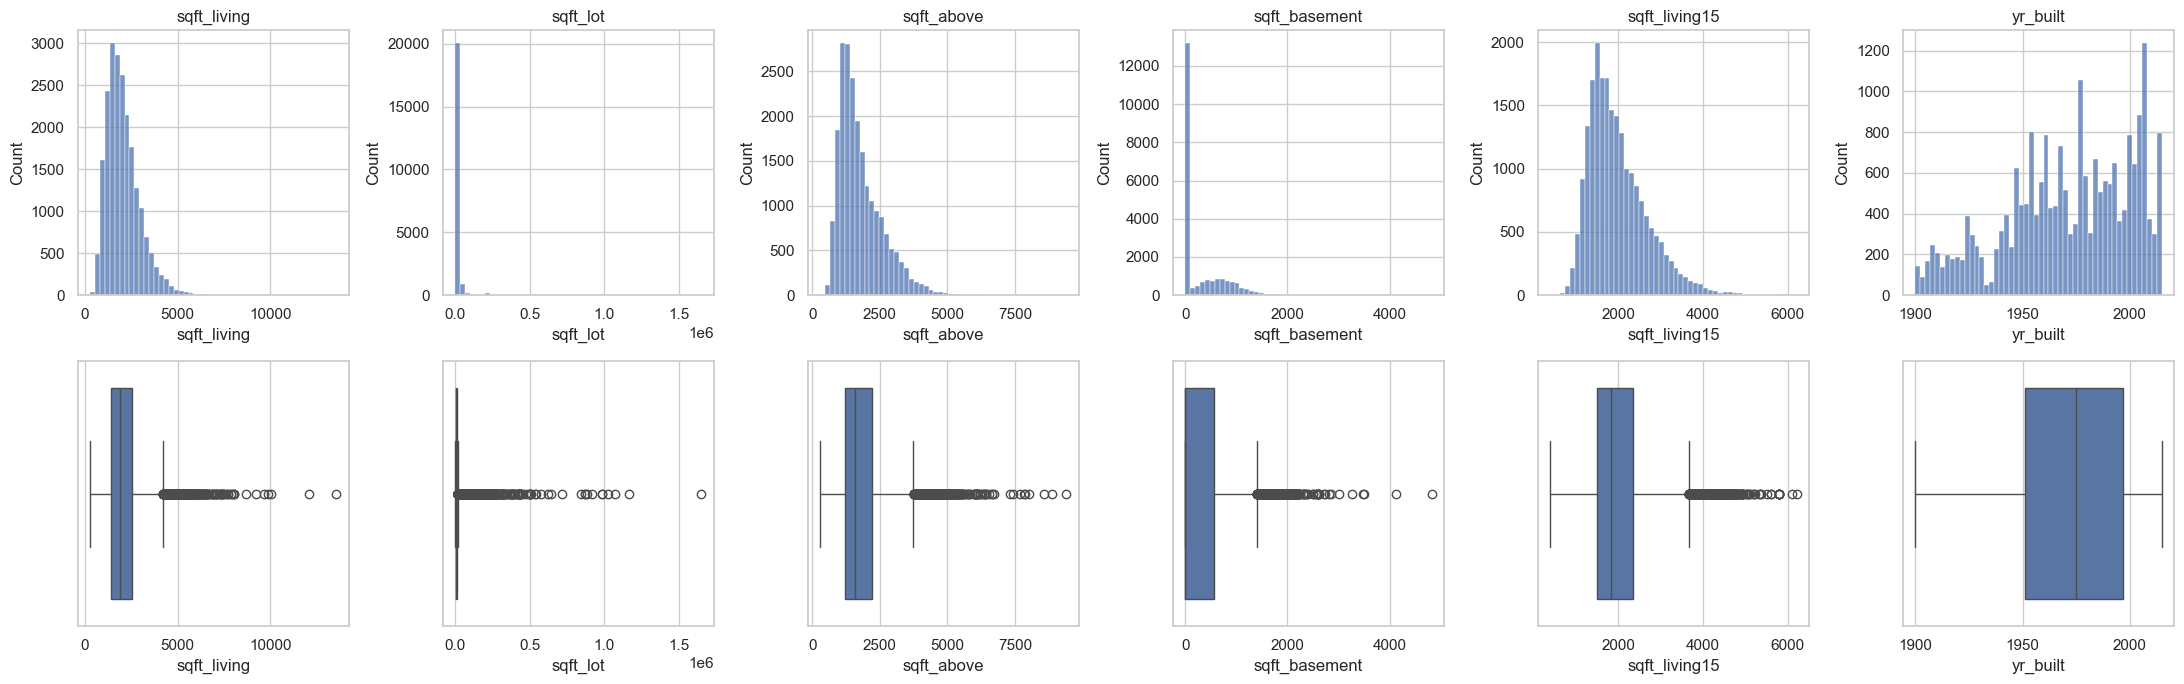

In [5]:
num_cols = ['sqft_living', 'sqft_lot', 'sqft_above', 'sqft_basement', 'sqft_living15', 'yr_built']
fig, axes = plt.subplots(2, 6, figsize=(22, 7))
for i, c in enumerate(num_cols):
    sns.histplot(df[c], bins=50, ax=axes[0, i]); axes[0, i].set_title(c)
    sns.boxplot(x=df[c], ax=axes[1, i])
save('eda_numeric_univariate.png')
print(df[num_cols].skew().round(2))

Tỷ lệ waterfront = 1: 0.75%
       bedrooms  bathrooms  sqft_living     price
15870        33       1.75         1620  640000.0


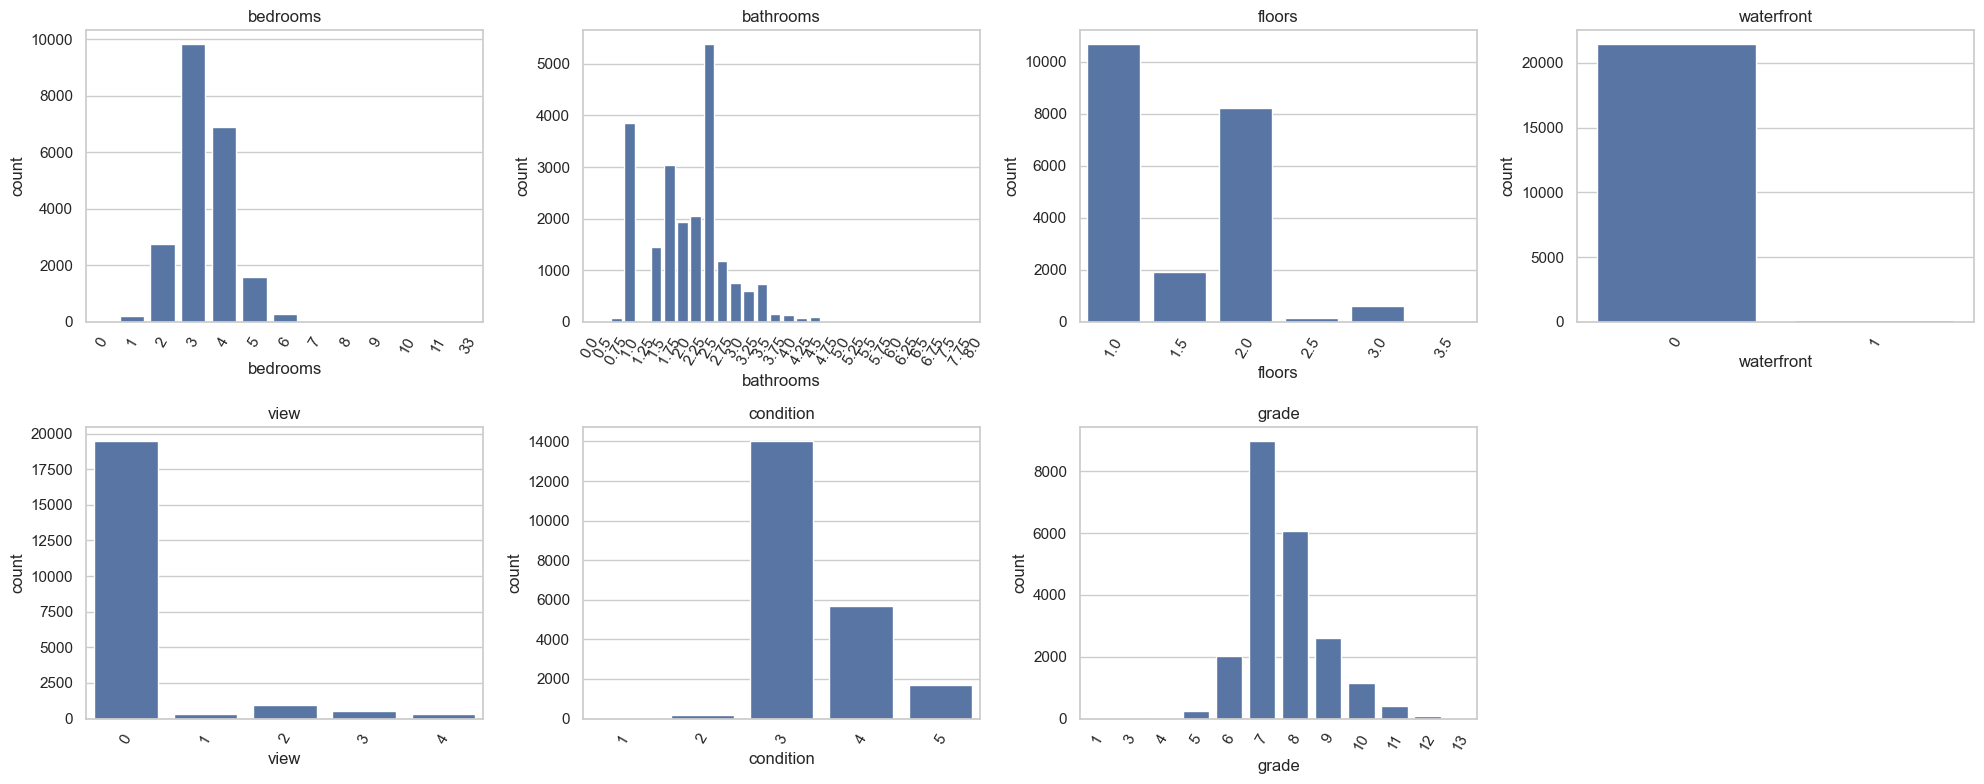

In [6]:
cat_cols = ['bedrooms', 'bathrooms', 'floors', 'waterfront', 'view', 'condition', 'grade']
fig, axes = plt.subplots(2, 4, figsize=(20, 8)); axes = axes.ravel()
for ax, c in zip(axes, cat_cols):
    sns.countplot(x=df[c], ax=ax); ax.set_title(c); ax.tick_params(axis='x', rotation=60)
axes[-1].axis('off')
save('eda_categorical_univariate.png')
print('Tỷ lệ waterfront = 1:', f"{df['waterfront'].mean():.2%}")
print(df[df['bedrooms'] >= 20][['bedrooms', 'bathrooms', 'sqft_living', 'price']])

## Đa biến

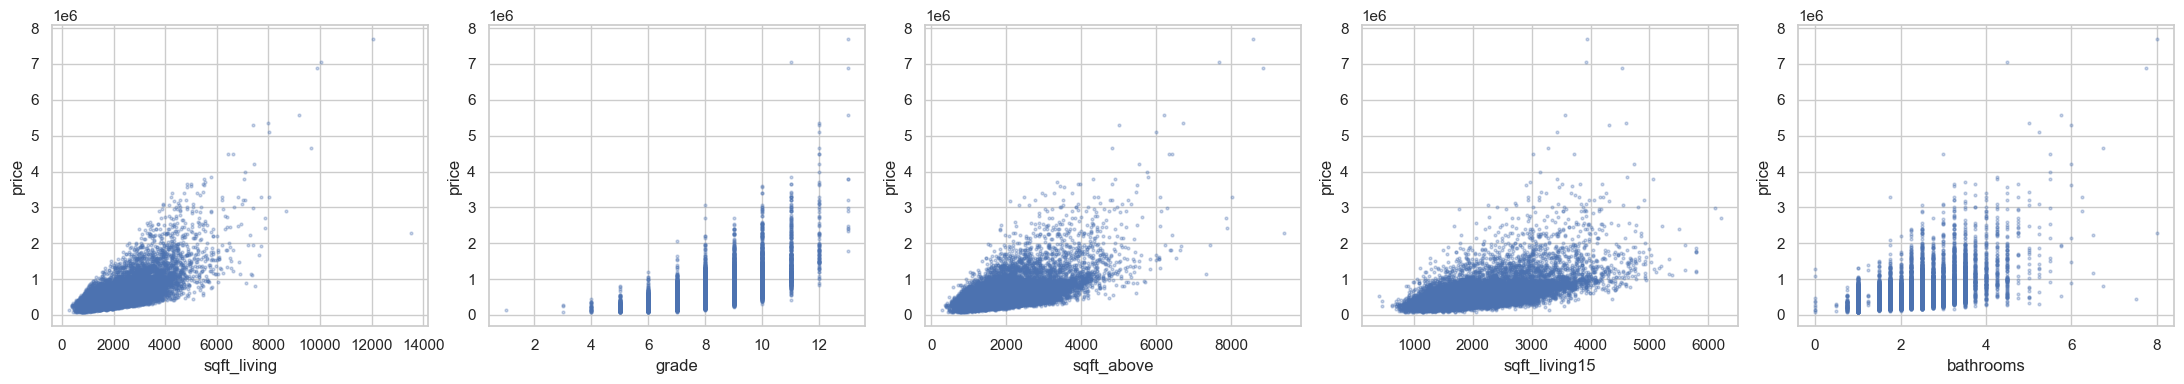

In [7]:
top = ['sqft_living', 'grade', 'sqft_above', 'sqft_living15', 'bathrooms']
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, c in zip(axes, top):
    ax.scatter(df[c], df['price'], s=4, alpha=.3); ax.set(xlabel=c, ylabel='price')
save('eda_scatter_price.png')

sqft_living      0.702
grade            0.667
sqft_above       0.606
sqft_living15    0.585
bathrooms        0.525
view             0.397
sqft_basement    0.324
bedrooms         0.308
lat              0.307
waterfront       0.266
floors           0.257
yr_renovated     0.126
sqft_lot         0.090
sqft_lot15       0.082
yr_built         0.054
condition        0.036
long             0.022
zipcode         -0.053
Name: price, dtype: float64


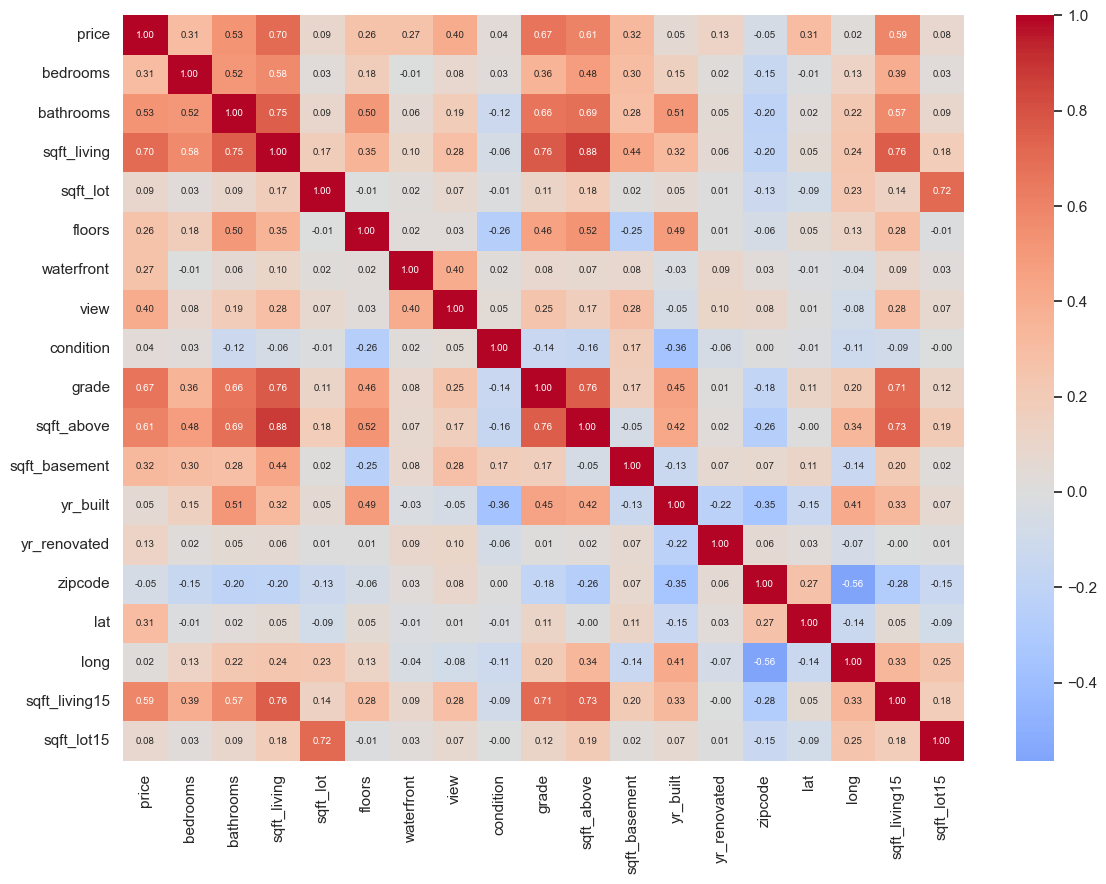

In [8]:
corr = df.drop(columns=['id', 'date']).select_dtypes('number').corr()
plt.figure(figsize=(12, 9)); sns.heatmap(corr, cmap='coolwarm', center=0, annot=True, fmt='.2f', annot_kws={'size': 7})
save('eda_correlation.png')
print(corr['price'].drop('price').sort_values(ascending=False).round(3))

waterfront
0     450000.0
1    1400000.0
Name: price, dtype: float64
grade
1      142000.0
3      262000.0
4      205000.0
5      228700.0
6      275276.5
7      375000.0
8      510000.0
9      720000.0
10     914327.0
11    1284000.0
12    1817500.0
13    2983000.0
Name: price, dtype: float64


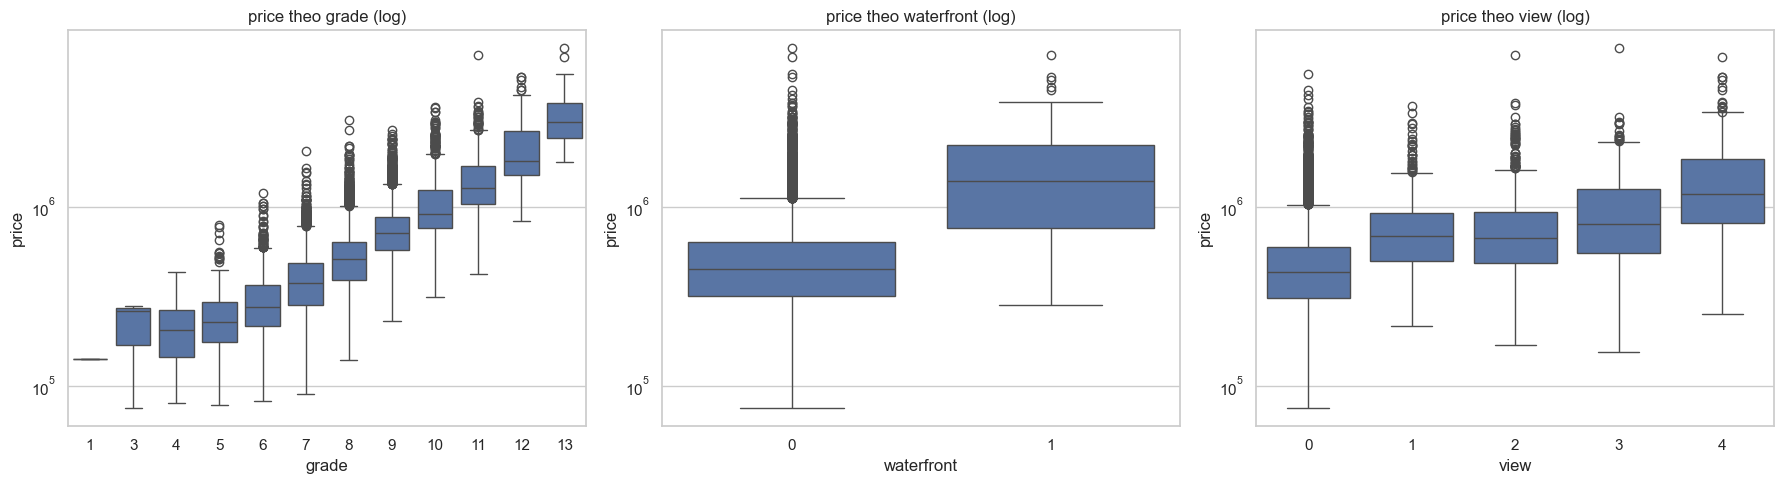

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, c in zip(axes, ['grade', 'waterfront', 'view']):
    sns.boxplot(data=df, x=c, y='price', ax=ax); ax.set_yscale('log'); ax.set_title(f'price theo {c} (log)')
save('eda_price_by_category.png')
print(df.groupby('waterfront')['price'].median()); print(df.groupby('grade')['price'].median())

zipcode
98002     235000.0
98039    1892500.0
Name: price, dtype: float64


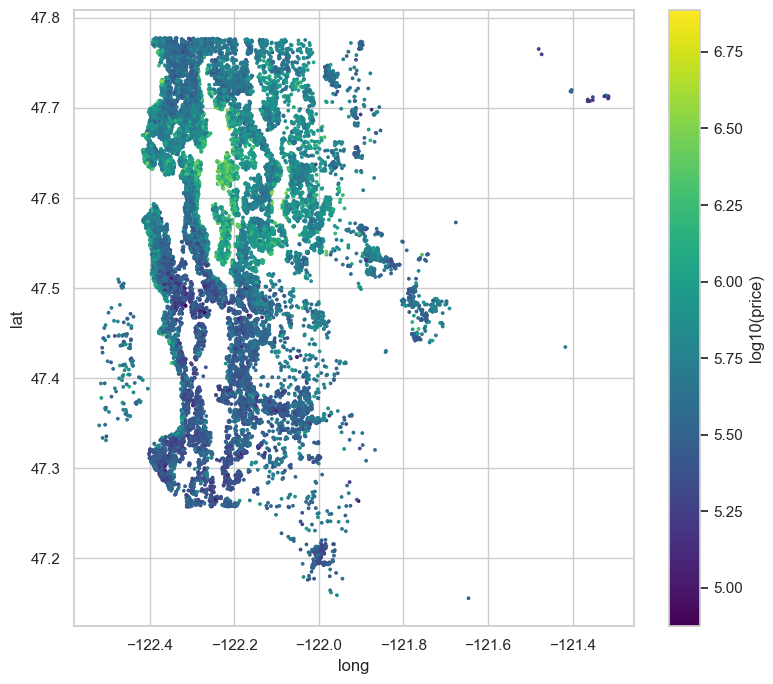

In [10]:
plt.figure(figsize=(8, 7))
sc = plt.scatter(df['long'], df['lat'], c=np.log10(df['price']), s=3, cmap='viridis')
plt.colorbar(sc, label='log10(price)'); plt.xlabel('long'); plt.ylabel('lat')
save('eda_geo_price.png')
zm = df.groupby('zipcode')['price'].median().sort_values()
print(zm.iloc[[0, -1]])